# 02 · ¿Será bien recibido? Clasificación y umbral por costos
**Responsable:** Persona A

**Pregunta:** con solo lo que se sabe del juego en la tienda (precio, géneros, etiquetas, plataformas, desarrollador…), ¿podemos anticipar si tendrá más de 80 % de reseñas positivas?

**Entrada:** `data/processed/juegos.parquet` · **Salida:** `outputs/pred_calidad.csv` (appid, p_bien_recibido) y `outputs/umbral.json`

Reglas que seguimos:
- **Sin fuga de datos:** ninguna columna derivada de reseñas, owners, playtime o metacritic (`C.COLUMNAS_PROHIBIDAS`). `construir_X` lo verifica con un `assert`.
- Todo el preprocesamiento va **dentro del Pipeline** (escalado y *target encoding* del desarrollador se ajustan solo con los datos de entrenamiento de cada fold).
- Validación cruzada estratificada de 5 folds sobre el 80 %; el **20 % de examen se usa una sola vez**, al final.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, RocCurveDisplay)
from sklearn.inspection import permutation_importance

from src import config as C
from src.datos import cargar_juegos
from src.features import construir_X, NUMERICAS, CATEGORICAS

df = cargar_juegos()
X = construir_X(df)
y = df["bien_recibido"]
print(X.shape, f"positivos: {y.mean():.1%}")

(44568, 359) positivos: 52.8%


## 1. Separar el examen
El 20 % se aparta ahora y no se mira hasta la sección 4.

In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=C.SEMILLA)
print(f"entrenamiento: {len(X_tr):,}  ·  examen: {len(X_te):,}")

entrenamiento: 35,654  ·  examen: 8,914


## 2. Comparar modelos con validación cruzada
- **Perezoso** (`DummyClassifier`): siempre dice la clase más común. Es la línea base que hay que superar.
- **Regresión logística**, **Random Forest** y **boosting** (`HistGradientBoostingClassifier`).

In [3]:
otras = [c for c in X.columns if c not in NUMERICAS + CATEGORICAS]

def pipeline(modelo):
    pre = ColumnTransformer([
        ("num", StandardScaler(), NUMERICAS),
        ("te", TargetEncoder(random_state=C.SEMILLA), CATEGORICAS),  # desarrollador / publicador
        ("bin", "passthrough", otras),
    ])
    return Pipeline([("pre", pre), ("modelo", modelo)])

modelos = {
    "perezoso": DummyClassifier(strategy="most_frequent"),
    "logistica": LogisticRegression(max_iter=2000, C=0.5),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=C.SEMILLA),
    "boosting": HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, random_state=C.SEMILLA),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=C.SEMILLA)

filas = []
for nombre, modelo in modelos.items():
    r = cross_validate(pipeline(modelo), X_tr, y_tr, cv=cv,
                       scoring=["roc_auc", "precision", "recall", "accuracy"])
    filas.append({"modelo": nombre,
                  **{m: r[f"test_{m}"].mean() for m in ["roc_auc", "precision", "recall", "accuracy"]},
                  "auc_std": r["test_roc_auc"].std()})
resultados_cv = pd.DataFrame(filas).set_index("modelo").round(3)
resultados_cv.to_csv(C.OUTPUTS / "02_resultados_cv.csv")
resultados_cv

,roc_auc,precision,recall,accuracy,auc_std
modelo,,,,,
perezoso,0.500,0.528,1.000,0.528,0.000
logistica,0.776,0.719,0.728,0.706,0.004
random_forest,0.795,0.721,0.771,0.722,0.004
boosting,0.799,0.732,0.757,0.726,0.004


In [4]:
mejor = resultados_cv["roc_auc"].idxmax()
print("Modelo elegido (mayor AUC en CV):", mejor)

Modelo elegido (mayor AUC en CV): boosting


## 3. Elegir el umbral según el costo
El 0.5 es una costumbre, no una decisión. Para nuestro jugador:
- **Comprar un juego malo** (falso positivo) = pierde el dinero completo → costo `C.COSTO_COMPRAR_MALO = 1`.
- **Perderse un juego bueno** (falso negativo) = duele menos, porque en la oferta hay muchos sustitutos buenos → `C.COSTO_PERDER_BUENO = 0.5`.

Para no tocar el examen, el umbral se elige con las **predicciones fuera de fold** (`cross_val_predict`) del conjunto de entrenamiento.

umbral = 0.66  ·  costo 0.187 vs 0.210 con 0.5


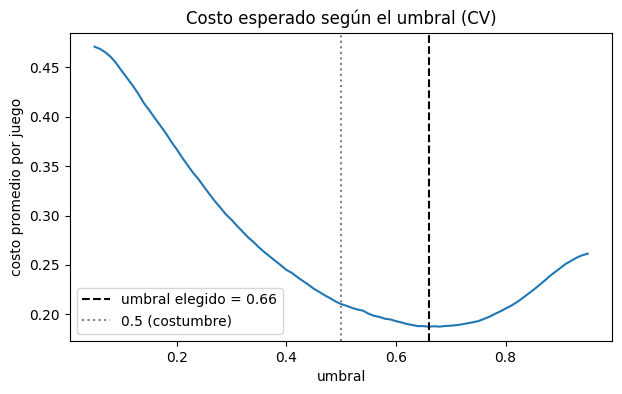

In [5]:
p_oof = cross_val_predict(pipeline(modelos[mejor]), X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]

def costo_promedio(y_true, p, umbral, c_fp=C.COSTO_COMPRAR_MALO, c_fn=C.COSTO_PERDER_BUENO):
    pred = p >= umbral
    fp = ((pred == 1) & (y_true == 0)).sum()
    fn = ((pred == 0) & (y_true == 1)).sum()
    return (c_fp * fp + c_fn * fn) / len(y_true)

umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)
costos = np.array([costo_promedio(y_tr.values, p_oof, u) for u in umbrales])
umbral = float(umbrales[costos.argmin()])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(umbrales, costos)
ax.axvline(umbral, color="k", ls="--", label=f"umbral elegido = {umbral:.2f}")
ax.axvline(0.5, color="grey", ls=":", label="0.5 (costumbre)")
ax.set(xlabel="umbral", ylabel="costo promedio por juego", title="Costo esperado según el umbral (CV)")
ax.legend()
fig.savefig(C.FIGURAS / "02_costo_umbral.png", dpi=120, bbox_inches="tight")
print(f"umbral = {umbral:.2f}  ·  costo {costos.min():.3f} vs {costo_promedio(y_tr.values, p_oof, 0.5):.3f} con 0.5")

**Sensibilidad:** ¿cómo cambia el umbral si perderse un bueno duele más o menos?

In [6]:
sens = []
for c_fn in [0.25, 0.5, 1.0, 2.0]:
    cs = [costo_promedio(y_tr.values, p_oof, u, c_fp=1.0, c_fn=c_fn) for u in umbrales]
    u = umbrales[int(np.argmin(cs))]
    pred = p_oof >= u
    sens.append({"costo_perder_bueno / costo_comprar_malo": c_fn, "umbral": u,
                 "precision": precision_score(y_tr, pred), "recall": recall_score(y_tr, pred),
                 "% de juegos que pasan": pred.mean()})
pd.DataFrame(sens).round(3)

,costo_perder_bueno / costo_comprar_malo,umbral,precision,recall,% de juegos que pasan
0,0.25,0.79,0.874,0.325,0.196
1,0.50,0.66,0.805,0.561,0.367
2,1.00,0.50,0.732,0.757,0.546
3,2.00,0.33,0.654,0.899,0.725


## 4. Evaluación final en el examen (una sola vez)
Se entrena el modelo elegido con todo el 80 % y se evalúa en el 20 % que no se había tocado.

In [7]:
final = pipeline(modelos[mejor]).fit(X_tr, y_tr)
p_te = final.predict_proba(X_te)[:, 1]

def metricas(u):
    pred = p_te >= u
    return {"AUC": roc_auc_score(y_te, p_te), "precision": precision_score(y_te, pred),
            "recall": recall_score(y_te, pred), "accuracy": accuracy_score(y_te, pred),
            "costo": costo_promedio(y_te.values, p_te, u)}

examen = pd.DataFrame({f"umbral {umbral:.2f}": metricas(umbral), "umbral 0.50": metricas(0.5),
                       "perezoso": {"AUC": 0.5, "precision": y_te.mean(), "recall": 1.0,
                                    "accuracy": y_te.mean(), "costo": C.COSTO_COMPRAR_MALO * (1 - y_te.mean())}}).round(3)
examen.to_csv(C.OUTPUTS / "02_resultados_examen.csv")
examen

,umbral 0.66,umbral 0.50,perezoso
AUC,0.811,0.811,0.500
precision,0.815,0.736,0.527
recall,0.577,0.767,1.000
accuracy,0.708,0.732,0.527
costo,0.180,0.206,0.473


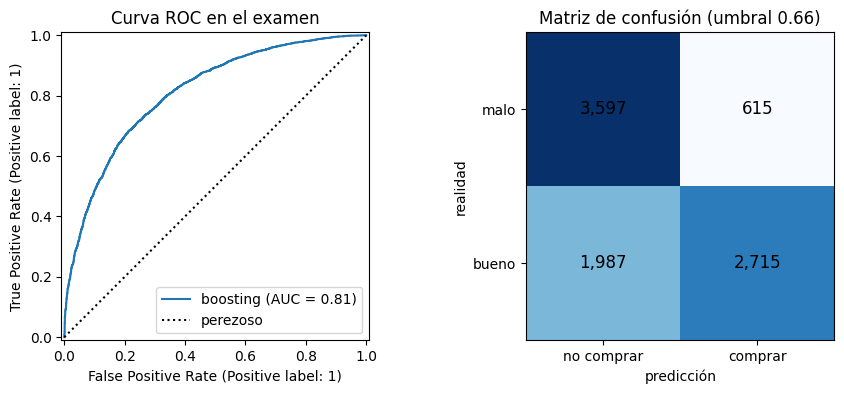

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_te, p_te, ax=axes[0], name=mejor)
axes[0].plot([0, 1], [0, 1], "k:", label="perezoso")
axes[0].set_title("Curva ROC en el examen"); axes[0].legend()

cm = confusion_matrix(y_te, p_te >= umbral)
axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center", fontsize=12)
axes[1].set_xticks([0, 1], ["no comprar", "comprar"]); axes[1].set_yticks([0, 1], ["malo", "bueno"])
axes[1].set(xlabel="predicción", ylabel="realidad", title=f"Matriz de confusión (umbral {umbral:.2f})")
fig.savefig(C.FIGURAS / "02_roc_confusion.png", dpi=120, bbox_inches="tight")

### ¿Qué variables pesan más? (importancia por permutación en el examen)

antiguedad_anios             0.0481
publicador                   0.0328
desarrollador                0.0150
log_precio                   0.0051
tag_Pixel Graphics           0.0045
n_idiomas                    0.0037
log_logros                   0.0026
cat_Steam Cloud              0.0025
tag_Classic                  0.0022
tag_Cute                     0.0020
tag_2D                       0.0018
tag_Great Soundtrack         0.0018
tag_Puzzle                   0.0017
cat_Remote Play on Tablet    0.0015
cat_Family Sharing           0.0015
dtype: float64

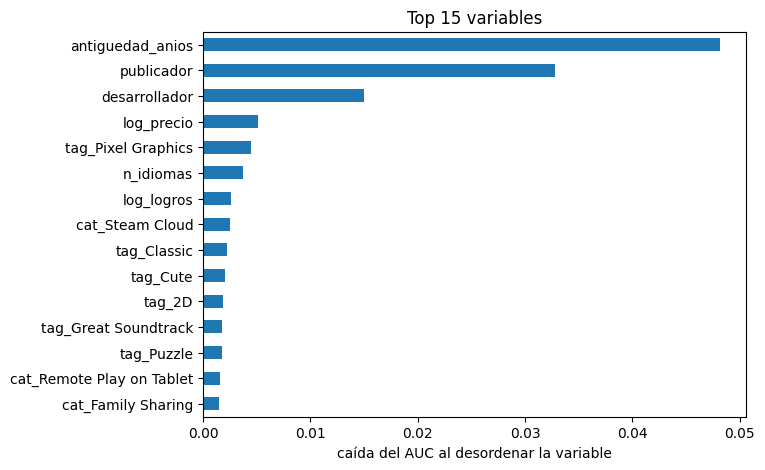

In [9]:
muestra = X_te.sample(3000, random_state=C.SEMILLA)
imp = permutation_importance(final, muestra, y_te.loc[muestra.index], scoring="roc_auc",
                             n_repeats=3, random_state=C.SEMILLA, n_jobs=-1)
importancias = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(7, 5))
importancias[::-1].plot.barh(ax=ax)
ax.set(xlabel="caída del AUC al desordenar la variable", title="Top 15 variables")
fig.savefig(C.FIGURAS / "02_importancia.png", dpi=120, bbox_inches="tight")
importancias.round(4)

<!-- seccion-4.1 -->
## 4.1 ¿Dónde falla el modelo y con quién?
Un AUC de 0.81 es un promedio: puede esconder grupos de juegos donde el modelo casi adivina. Aquí se parte el **examen** por grupos y se mide cada uno por separado.

- Se usan las mismas predicciones del examen de la sección 4. **No se cambia el modelo ni el umbral** con esto: es un diagnóstico, así que el examen se sigue usando una sola vez para decidir.
- Las reseñas (`total_resenas`) **no son predictor** (están en `C.COLUMNAS_PROHIBIDAS`), pero sí sirven para describir con quién falla.
- **Desarrollador nuevo** = ninguno de sus desarrolladores tiene juegos en el entrenamiento. Para ellos el *target encoding* no sabe nada y usa el promedio general.
- `costo` = costo promedio por juego con el umbral elegido (comprar un malo = 1, perderse un bueno = 0.5). Es la métrica de la decisión.

In [10]:
ex = df.loc[X_te.index, ["nombre", "total_resenas", "antiguedad_anios", "precio_lista_usd",
                         "generos", "desarrolladores", "pct_positivo"]].copy()
ex["real"] = y_te.astype(bool).values
ex["p"] = p_te
ex["compra"] = p_te >= umbral

devs_entrenamiento = set(df.loc[X_tr.index, "desarrolladores"].explode().dropna())
ex["desarrollador"] = np.where(ex["desarrolladores"].apply(lambda ds: any(d in devs_entrenamiento for d in ds)),
                               "conocido", "nuevo")
ex["reseñas"] = pd.cut(ex["total_resenas"], [C.MIN_RESENAS - 1, 50, 200, 1000, np.inf],
                       labels=["20 a 50", "50 a 200", "200 a 1,000", "más de 1,000"])
ex["antigüedad"] = pd.cut(ex["antiguedad_anios"], C.CORTES_ANTIGUEDAD, labels=C.GRUPOS_ANTIGUEDAD,
                          include_lowest=True)
ex["precio"] = pd.cut(ex["precio_lista_usd"], [-0.01, 0, 5, 15, 30, np.inf],
                      labels=["gratis", "hasta 5 USD", "5 a 15 USD", "15 a 30 USD", "más de 30 USD"])
GENEROS = ["Indie", "Action", "Adventure", "Casual", "Simulation", "Strategy", "RPG", "Early Access"]


def medir(variable, grupo, d):
    return {"variable": variable, "grupo": grupo, "juegos": len(d), "% bien recibidos": d["real"].mean(),
            "AUC": roc_auc_score(d["real"], d["p"]) if d["real"].nunique() == 2 else np.nan,
            "precision": precision_score(d["real"], d["compra"], zero_division=0),
            "recall": recall_score(d["real"], d["compra"], zero_division=0),
            "costo": costo_promedio(d["real"].values, d["p"], umbral)}


filas = [medir("todos", "examen completo", ex)]
for col in ["reseñas", "desarrollador", "antigüedad", "precio"]:
    filas += [medir(col, g, d) for g, d in ex.groupby(col, observed=True)]
filas += [medir("género", g, ex[ex["generos"].apply(lambda gs, g=g: g in gs)]) for g in GENEROS]

por_grupo = pd.DataFrame(filas).set_index(["variable", "grupo"])
por_grupo.round(3)

juegos  % bien recibidos    AUC  precision  \
variable      grupo                                                         
todos         examen completo    8914             0.527  0.811      0.815   
reseñas       20 a 50            2825             0.482  0.817      0.778   
              50 a 200           2758             0.472  0.812      0.790   
              200 a 1,000        1916             0.553  0.790      0.811   
              más de 1,000       1415             0.693  0.814      0.913   
desarrollador conocido           4963             0.530  0.819      0.823   
              nuevo              3951             0.525  0.801      0.805   
antigüedad    0 a 2 años          570             0.725  0.787      0.864   
              2 a 5 años         2649             0.616  0.796      0.816   
              5 a 10 años        4048             0.486  0.803      0.801   
              más de 10 años     1647             0.417  0.806      0.814   
precio        gratis             1188             0.449  0.803      0.787   
              hasta 5 USD        3263             0.508  0.818      0.811   
              5 a 15 USD         2959             0.573  0.802      0.813   
              15 a 30 USD        1226             0.547  0.808      0.843   
              más de 30 USD       278             0.518  0.808      0.860   
género        Indie              6320             0.538  0.811      0.814   
              Action             3760             0.491  0.806      0.800   
              Adventure          3794             0.538  0.815      0.817   
              Casual             3201             0.554  0.812      0.822   
              Simulation         2088             0.455  0.800      0.811   
              Strategy           1908             0.480  0.791      0.812   
              RPG                1828             0.497  0.801      0.783   
              Early Access        675             0.419  0.792      0.775   

                               recall  costo  
variable      grupo                           
todos         examen completo   0.577  0.180  
reseñas       20 a 50           0.580  0.181  
              50 a 200          0.579  0.172  
              200 a 1,000       0.535  0.198  
              más de 1,000      0.617  0.173  
desarrollador conocido          0.604  0.174  
              nuevo             0.544  0.189  
antigüedad    0 a 2 años        0.755  0.175  
              2 a 5 años        0.682  0.193  
              5 a 10 años       0.509  0.181  
              más de 10 años    0.419  0.161  
precio        gratis            0.436  0.180  
              hasta 5 USD       0.579  0.175  
              5 a 15 USD        0.620  0.191  
              15 a 30 USD       0.592  0.172  
              más de 30 USD     0.514  0.169  
género        Indie             0.595  0.182  
              Action            0.534  0.180  
              Adventure         0.600  0.180  
              Casual            0.615  0.180  
              Simulation        0.466  0.171  
              Strategy          0.496  0.176  
              RPG               0.541  0.188  
              Early Access      0.353  0.179

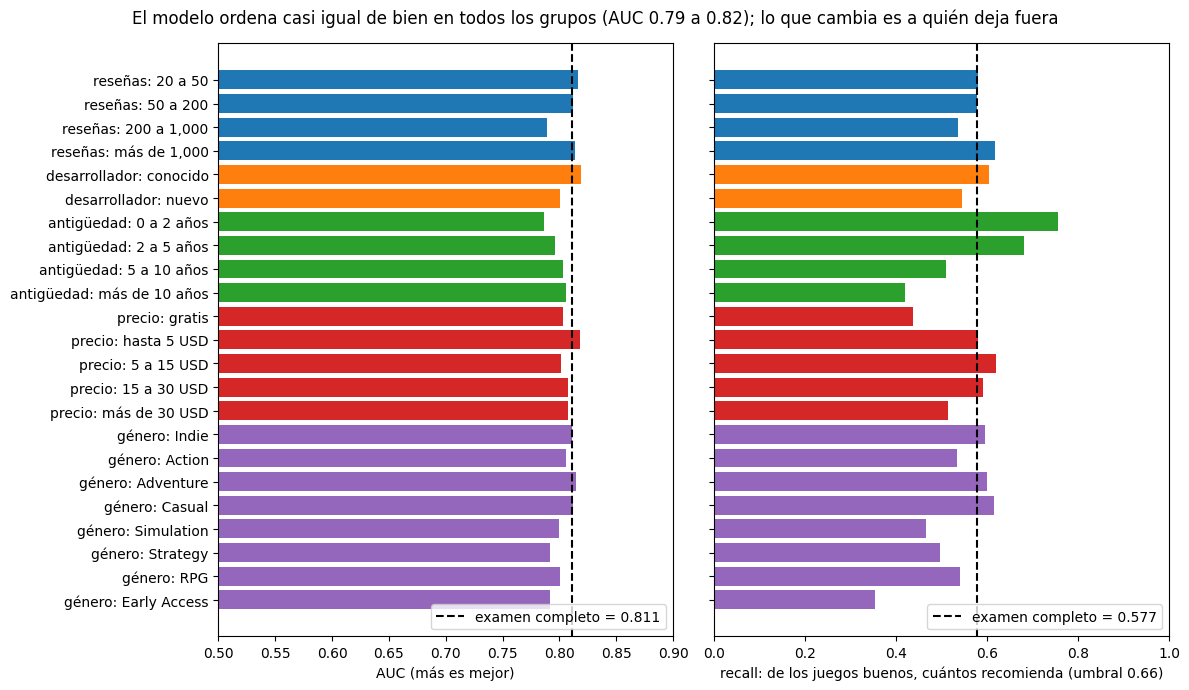

In [11]:
graf = por_grupo.drop(index="todos", level="variable").reset_index()
graf["etiqueta"] = graf["variable"] + ": " + graf["grupo"].astype(str)
colores = dict(zip(graf["variable"].unique(), plt.cm.tab10.colors))
auc_total = por_grupo.loc[("todos", "examen completo"), "AUC"]
recall_total = por_grupo.loc[("todos", "examen completo"), "recall"]

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
for ax, col, total in [(axes[0], "AUC", auc_total), (axes[1], "recall", recall_total)]:
    ax.barh(graf["etiqueta"], graf[col], color=[colores[v] for v in graf["variable"]])
    ax.axvline(total, color="k", ls="--", label=f"examen completo = {total:.3f}")
    ax.legend(loc="lower right")
axes[0].set(xlabel="AUC (más es mejor)", xlim=(0.5, 0.9))
axes[1].set(xlabel="recall: de los juegos buenos, cuántos recomienda (umbral 0.66)", xlim=(0, 1))
axes[0].invert_yaxis()
fig.suptitle('El modelo ordena casi igual de bien en todos los grupos (AUC 0.79 a 0.82); lo que cambia es a quién deja fuera')
fig.tight_layout()
fig.savefig(C.FIGURAS / "02_donde_falla.png", dpi=120, bbox_inches="tight")

**Los errores más caros:** juegos que el modelo recomendaría con mucha seguridad y que en realidad no son bien recibidos (falsos positivos con la probabilidad más alta).

In [12]:
caros = ex[ex["compra"] & ~ex["real"]].nlargest(10, "p")
caros[["nombre", "p", "pct_positivo", "total_resenas", "desarrollador", "antigüedad"]].round(3)

,nombre,p,pct_positivo,total_resenas,desarrollador,antigüedad
12046,Hidden Cats: Magic Forest,0.959,0.600,55,conocido,2 a 5 años
4151,Mining Cats,0.952,0.764,55,conocido,2 a 5 años
43811,My Lovely Daughter,0.952,0.699,1261,conocido,5 a 10 años
40212,NeuroVoider,0.945,0.762,766,conocido,más de 10 años
12643,Street Fighter V,0.940,0.676,43651,conocido,más de 10 años
37232,World of Mines Creator's Edition,0.921,0.686,51,conocido,2 a 5 años
37138,Super Dark Deception,0.917,0.727,425,conocido,2 a 5 años
6995,Flying Neko Delivery,0.915,0.621,29,conocido,2 a 5 años
457,Neon Rider Classic,0.904,0.735,34,nuevo,2 a 5 años
10596,Giana Sisters: Twisted Dreams,0.904,0.776,1895,conocido,más de 10 años


**Lo que muestra el diagnóstico:**

1. **El modelo ordena casi igual de bien en todos los grupos.** El AUC va de 0.79 a 0.82 en todos los grupos (examen completo: 0.81). No hay un grupo donde el modelo adivine al azar.

2. **Lo que cambia entre grupos es a quién deja fuera (el recall).** Con el mismo umbral de 0.66:
   - **Juegos viejos:** de los que tienen más de 10 años, detecta solo el **42 %** de los buenos; de los de 0 a 2 años, el **76 %**. La antigüedad es la variable que más pesa en el modelo, y como los juegos viejos son peor recibidos en promedio (42 % contra 73 %), el modelo les baja la probabilidad a todos, incluidos los clásicos buenos.
   - **Early Access** (35 %), **gratis** (44 %), **Simulation** (47 %) y **Strategy** (50 %) también quedan muy por debajo del 58 % general.
   - **Con quién falla:** a un jugador al que le gustan los clásicos, los simuladores o la estrategia, el modelo le muestra menos juegos buenos de los que existen. No le hace comprar más malos (en esos tres grupos la precision se mantiene en 0.81), pero sí le esconde opciones.

3. **Donde más se equivoca comprando (la precision más baja):** Early Access (0.775), RPG (0.783), juegos con 20 a 50 reseñas (0.778) y gratis (0.787). En los juegos con más de 1,000 reseñas, 9 de cada 10 recomendados son buenos (0.913).

4. **Los desarrolladores nuevos salen perjudicados.** Si ninguno de los desarrolladores del juego tiene juegos en el entrenamiento, el AUC baja de 0.819 a 0.801, el recall de 0.60 a 0.54 y el costo sube de 0.174 a 0.189. El modelo se apoya en la reputación del desarrollador, y un estudio nuevo no tiene.

5. **Esa misma reputación causa los errores más caros.** 9 de los 10 errores más seguros (probabilidad de 0.90 a 0.96) son de desarrolladores **conocidos**: *Street Fighter V* (0.94, pero 68 % positivo con 43,651 reseñas) o *Hidden Cats: Magic Forest* y *Mining Cats* (0.96 y 0.95). El *target encoding* le pasa a cada juego el promedio de los otros juegos de su desarrollador: cuando un estudio con buena fama saca un juego flojo, el modelo lo recomienda con mucha seguridad.

6. **Parte del error está en la etiqueta, no en el modelo.** Varios de esos errores tienen entre 29 y 55 reseñas: con tan pocas, el % positivo cambia mucho con un par de reseñas más. Eso ayuda a explicar por qué la precision es más baja en el grupo de 20 a 50 reseñas.

**Qué hacemos con esto:** nada cambia en el modelo ni en el umbral, porque el examen ya se usó. En la decisión (notebook 05), las reseñas reales confirman lo que dice el modelo, y eso corrige justo los errores de los puntos 3 y 5. Lo que queda sin corregir es el punto 2: los clásicos, el Early Access y los simuladores buenos tienen menos posibilidades de entrar a la lista.

## 5. Predicciones para la decisión (entrega a Persona C)
Para que ninguna probabilidad venga de un modelo que ya vio ese juego:
- juegos de **entrenamiento** → probabilidad fuera de fold (`p_oof`)
- juegos de **examen** → probabilidad del modelo final (que no los vio)

In [13]:
pred = pd.concat([
    pd.DataFrame({"appid": df.loc[X_tr.index, "appid"], "p_bien_recibido": p_oof, "en_examen": False}),
    pd.DataFrame({"appid": df.loc[X_te.index, "appid"], "p_bien_recibido": p_te, "en_examen": True}),
])
pred["pasa_umbral"] = pred["p_bien_recibido"] >= umbral
pred.to_csv(C.OUTPUTS / "pred_calidad.csv", index=False)

(C.OUTPUTS / "umbral.json").write_text(json.dumps({
    "modelo": mejor, "umbral": umbral,
    "costo_comprar_malo": C.COSTO_COMPRAR_MALO, "costo_perder_bueno": C.COSTO_PERDER_BUENO,
    "auc_examen": round(float(roc_auc_score(y_te, p_te)), 4),
}, indent=2))
print(f"{len(pred):,} juegos guardados · pasan el umbral: {pred['pasa_umbral'].mean():.1%}")
pred.head()

44,568 juegos guardados · pasan el umbral: 36.9%


,appid,p_bien_recibido,en_examen,pasa_umbral
40961,1857740,0.544009,False,False
15703,1127820,0.685212,False,True
31488,355410,0.324611,False,False
22939,925100,0.111376,False,False
33214,2416460,0.343784,False,False


## Conclusiones

**1. Sí se puede anticipar la calidad, con un poder moderado.** El boosting llega a **AUC ≈ 0.80 en CV y 0.81 en el examen**, frente a 0.50 del modelo perezoso. Random Forest queda casi igual (0.795) y la regresión logística un poco atrás (0.776). La diferencia CV → examen es pequeña, así que no hay señales de sobreajuste.

**2. El umbral cambia la decisión.** Con nuestros costos (comprar un malo = 1, perder un bueno = 0.5) el umbral óptimo es **0.66, no 0.5**. En el examen:
- la **precision sube de 0.74 a 0.82**: de cada 10 juegos que el modelo recomienda, 8 son realmente bien recibidos;
- a cambio, el recall baja (0.77 → 0.58): dejamos pasar varios buenos, lo cual es aceptable porque en la oferta sobran alternativas;
- el **costo esperado baja de 0.206 a 0.180** por juego (el perezoso cuesta 0.473).

La tabla de sensibilidad muestra que, si el jugador fuera más tolerante a perderse buenos (0.25), el umbral subiría a ~0.79 y solo pasaría el 20 % de los juegos.

**3. Qué pesa más:**
- **Antigüedad:** es de lo que más pesa, pero en promedio los juegos más viejos tienen peor % positivo (cerca de 85 % en los de 0 a 2 años contra 72 % en los de más de 10). Solo entre los muy reseñados casi no hay diferencia. La importancia dice cuánto ayuda a predecir, no en qué dirección, y la supervivencia no se puede medir aquí porque los juegos que salieron de la tienda no están en los datos. Esto también importa para la pregunta causal del notebook 04.
- **Publicador y desarrollador:** la reputación del estudio predice bastante.
- Después vienen el precio, los idiomas, los logros y algunas etiquetas (Pixel Graphics, Cute, Puzzle, Great Soundtrack).

**Limitaciones:**
- Las **etiquetas las ponen los usuarios** después del lanzamiento. Algunas ("Great Soundtrack", "Classic") reflejan en parte la opinión de los jugadores, así que el modelo es algo optimista para juegos *recién* lanzados.
- El *target encoding* del desarrollador favorece a estudios con historial. Para estudios nuevos, el modelo se apoya en el resto de variables.
- "Bien recibido" (> 80 %) es un corte arbitrario: un juego con 79 % cuenta como "malo".

**Entrega a Persona C:** `outputs/pred_calidad.csv` (44,568 juegos con `p_bien_recibido` y `pasa_umbral`) y `outputs/umbral.json`.